# Cambodia Road Crash Severity Model

This notebook follows the **CRISP-DM** data modeling process from start to finish.

| Step | Stage | Question it answers |
|---|---|---|
| 1 | Business understanding | What are we predicting, and what counts as success? |
| 2 | Data understanding | What is in the data, and what is wrong with it? |
| 3 | Data preparation | Which rows and features are valid, and how do we split them? |
| 4 | Modeling | Which algorithm works best on the training data? |
| 5 | Evaluation | How does it do on data it has never seen, and can we trust it? |
| 6 | Deployment | How do we save and use it, and what are its limits? |

**Input:** `Road_Accidents_Extracted.xlsx` in the same folder as this notebook. Run with **Kernel > Restart & Run All**.

## Setup

In [1]:
# Installs anything missing. On a machine where pandas fails with "No module named pytz", this fixes it.
import importlib.util
import subprocess
import sys

required = {"pandas": "pandas", "numpy": "numpy", "sklearn": "scikit-learn", "matplotlib": "matplotlib",
            "openpyxl": "openpyxl", "joblib": "joblib", "pytz": "pytz"}
missing = [pip_name for module, pip_name in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("All packages available")

All packages available


In [2]:
%matplotlib inline
import os
import re
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore", category=UserWarning)
os.environ["PYTHONWARNINGS"] = "ignore::UserWarning"  # also silences the parallel worker processes
pd.set_option("display.max_columns", 40, "display.width", 140, "display.max_colwidth", 70)

DATA_PATH = Path("../data/raw/news/Road_Accidents_Extracted.xlsx")
MODEL_PATH = Path("../models/road_severity_model.joblib")
RANDOM_STATE = 42

BLUE, ORANGE, GREY, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#c9c8c2", "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GREY,
                     "axes.labelcolor": MUTED, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": False, "font.size": 10, "legend.frameon": False})


def label_bars(ax, fmt="{:,.0f}", horizontal=True):
    """Write each bar's value next to it, in text ink rather than the series color."""
    for bar in ax.patches:
        if horizontal:
            ax.annotate(fmt.format(bar.get_width()), (bar.get_width(), bar.get_y() + bar.get_height() / 2),
                        xytext=(4, 0), textcoords="offset points", va="center", color=MUTED, fontsize=9)
        else:
            ax.annotate(fmt.format(bar.get_height()), (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                        xytext=(0, 3), textcoords="offset points", ha="center", color=MUTED, fontsize=9)

---
# Step 1. Business understanding

**Problem.** Road crashes kill well over 1,000 people a year in Cambodia, and motorcyclists are most of those deaths. Planners need to know which circumstances are linked with the worst outcomes.

**Modeling question.** Given the circumstances of a reported crash (when, where, road, vehicles, stated factors), was it fatal?

| Item | Decision |
|---|---|
| Task | Binary classification |
| Target | `is_fatal` = 1 if the article reports at least one death, otherwise 0 |
| Unit of analysis | One crash |
| Main metrics | PR-AUC and ROC-AUC, because both judge ranking across all thresholds |
| Supporting metrics | Recall, precision and F1 for the Fatal class |
| Baseline | A model that always predicts the average fatal rate |

**Success criterion, set before seeing results:** on the 2024 holdout, the lower end of the 95% interval for ROC-AUC must be above 0.60, and PR-AUC must clearly beat the baseline.

**What this model cannot do.** The data contains crashes journalists chose to report, so the model learns what makes a *reported* crash fatal. It does not measure real-world crash risk, and it shows association, not cause.

---
# Step 2. Data understanding

## 2.1 Load the data and see what survives filtering

In [3]:
raw = pd.read_excel(DATA_PATH, sheet_name="Accidents", parse_dates=["publish_date", "incident_date"])
factor_cols = [c for c in raw.columns if c.startswith("factor_") and c != "factor_evidence"]  # factor_evidence is text
print(f"{raw.shape[0]:,} rows, {raw.shape[1]} columns")

funnel = pd.Series({
    "All rows in source": len(raw),
    "Crash reports (single crash in Cambodia)": (raw.record_type == "Crash report").sum(),
    "...and first record of each crash": ((raw.record_type == "Crash report") & (raw.is_primary_record == 1)).sum(),
    "...and text appears original (analysis_ready)": (raw.analysis_ready == 1).sum(),
    "...and severity is stated": ((raw.analysis_ready == 1) & (raw.severity != "Not stated")).sum(),
    "...and year is known (usable for modeling)": ((raw.analysis_ready == 1) & (raw.severity != "Not stated") & raw.year.notna()).sum(),
}, name="rows")
display(funnel.to_frame())
display(raw.groupby(["record_type", "text_provenance"]).size().unstack(fill_value=0))

1,074 rows, 67 columns


,rows
All rows in source,1074
Crash reports (single crash in Cambodia),943
...and first record of each crash,842
...and text appears original (analysis_ready),814
...and severity is stated,731
...and year is known (usable for modeling),691


text_provenance,Appears original,Split from multi-crash article,Suspected AI summary/rewrite
record_type,,,
Crash report,908,3,32
Feature/policy,6,0,0
Follow-up/legal,38,0,0
Foreign/celebrity news,39,0,0
Off-topic,8,0,0
Statistics/aggregate,38,0,2


## 2.2 How much of the real picture does the data cover?

These official totals come from news reports citing Cambodian authorities. Check them against the National Road Safety Committee's own annual reports before quoting them.

In [4]:
ready = raw[raw.analysis_ready == 1].copy()

official = pd.DataFrame({
    "year": [2021, 2022, 2023, 2024],
    "official_deaths": [1497, 1709, np.nan, np.nan],
    "official_crashes": [np.nan, np.nan, 3317, 2844],
}).set_index("year")
official["dataset_deaths"] = ready.groupby("year").deaths.sum().reindex(official.index)
official["dataset_crashes"] = ready.groupby("year").size().reindex(official.index)
official["coverage_of_deaths_%"] = (100 * official.dataset_deaths / official.official_deaths).round(1)
official["coverage_of_crashes_%"] = (100 * official.dataset_crashes / official.official_crashes).round(1)
display(official)

,official_deaths,official_crashes,dataset_deaths,dataset_crashes,coverage_of_deaths_%,coverage_of_crashes_%
year,,,,,,
2021,1497.0,NaN,47.0,171,3.1,NaN
2022,1709.0,NaN,56.0,156,3.3,NaN
2023,NaN,3317.0,80.0,56,NaN,1.7
2024,NaN,2844.0,160.0,193,NaN,6.8


## 2.3 Completeness of the key fields

In [5]:
key_fields = ["incident_date", "year", "incident_time", "time_of_day", "province", "district", "commune",
              "road_name", "collision_type", "stated_factors", "deaths", "injuries_total", "helmet_status"]
completeness = ready[key_fields].notna().mean().mul(100).round(1).sort_values().rename("% filled")
display(completeness.to_frame())
print("Note: blank does not always mean missing. For example, blank `deaths` is correct for a non-fatal crash.")

,% filled
helmet_status,3.2
injuries_total,32.3
deaths,37.0
road_name,47.8
incident_time,60.3
stated_factors,62.2
time_of_day,69.2
district,72.0
commune,76.5
collision_type,85.0


Note: blank does not always mean missing. For example, blank `deaths` is correct for a non-fatal crash.


## 2.4 Exploratory analysis

These four charts answer items 1 to 3 of the team's plan. Read them as **what was reported**, not what happened on the roads.

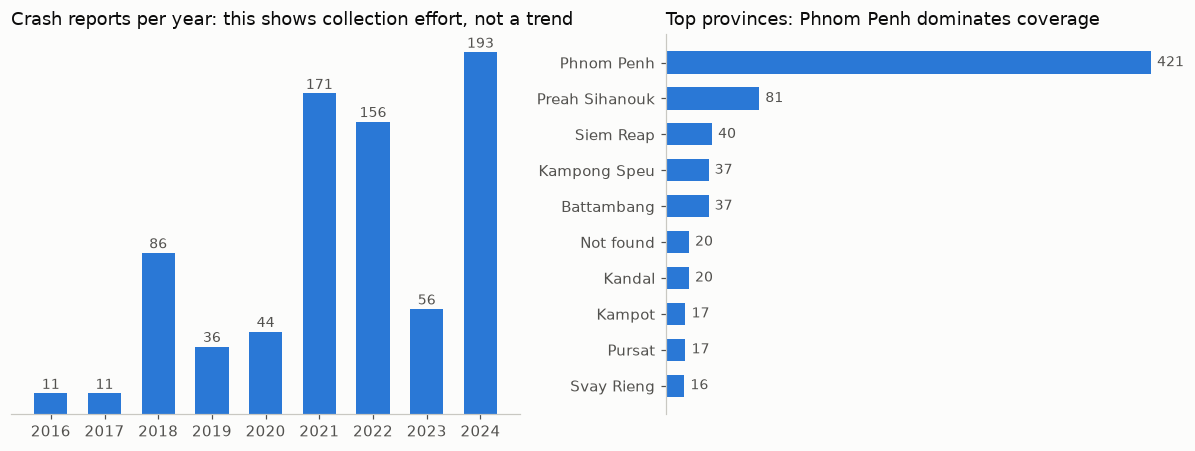

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

by_year = ready.dropna(subset=["year"]).astype({"year": int}).query("year >= 2016 and year <= 2024").groupby("year").size()
axes[0].bar(by_year.index.astype(str), by_year.values, color=BLUE, width=0.62)
label_bars(axes[0], horizontal=False)
axes[0].set_title("Crash reports per year: this shows collection effort, not a trend")
axes[0].set_yticks([])
axes[0].spines["left"].set_visible(False)

by_province = ready.province.fillna("Not found").value_counts().head(10).sort_values()
axes[1].barh(by_province.index, by_province.values, color=BLUE, height=0.62)
label_bars(axes[1])
axes[1].set_title("Top provinces: Phnom Penh dominates coverage")
axes[1].set_xticks([])
axes[1].spines["bottom"].set_visible(False)
plt.tight_layout()
plt.show()

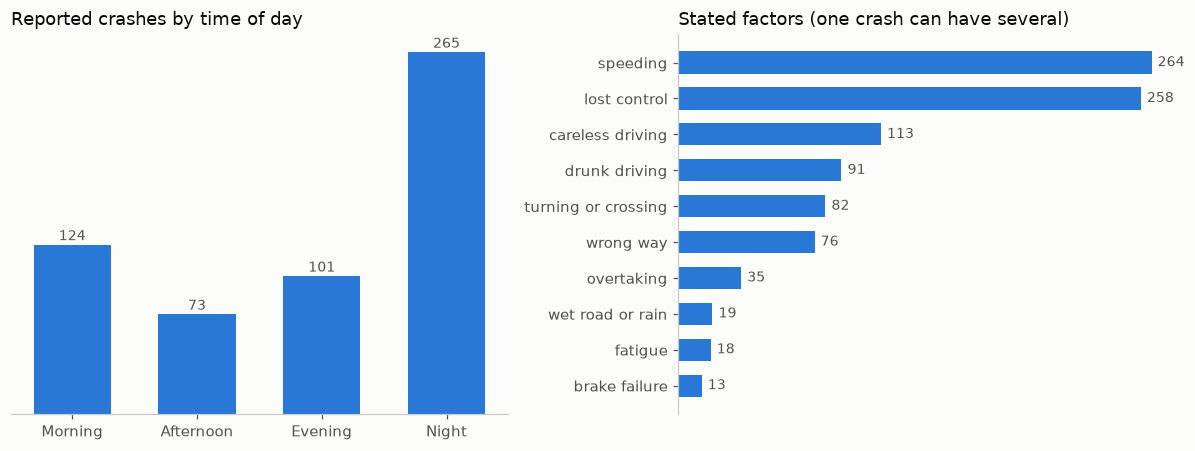

38% of crash reports state no factor at all.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

order = ["Morning (05-11)", "Afternoon (12-16)", "Evening (17-20)", "Night (21-04)"]
by_time = ready.time_of_day.value_counts().reindex(order)
axes[0].bar([o.split(" ")[0] for o in order], by_time.values, color=BLUE, width=0.62)
label_bars(axes[0], horizontal=False)
axes[0].set_title("Reported crashes by time of day")
axes[0].set_yticks([])
axes[0].spines["left"].set_visible(False)

by_factor = ready[factor_cols].sum().sort_values().tail(10)
axes[1].barh([c.replace("factor_", "").replace("_", " ") for c in by_factor.index], by_factor.values, color=BLUE, height=0.62)
label_bars(axes[1])
axes[1].set_title("Stated factors (one crash can have several)")
axes[1].set_xticks([])
axes[1].spines["bottom"].set_visible(False)
plt.tight_layout()
plt.show()

none_stated = (ready[factor_cols].sum(axis=1) == 0).mean()
print(f"{none_stated:.0%} of crash reports state no factor at all.")

## 2.5 Checking for reporting bias

If fatal crashes get longer articles, then longer articles mention more factors, and a factor can look linked to death simply because the story was longer. This check tells us how far to trust the factor features.

In [8]:
check = ready[ready.severity != "Not stated"].copy()
check["article_length"] = check.Crash_Description.str.len()
check["factors_stated"] = check[factor_cols].sum(axis=1)
display(check.groupby("severity")[["article_length", "factors_stated"]].mean().round(1)
        .assign(reports=check.severity.value_counts()))

,article_length,factors_stated,reports
severity,,,
Fatal,1357.4,1.4,301
Injury,1075.6,1.2,283
Property damage only,969.6,1.1,147


---
# Step 3. Data preparation

## 3.1 Select rows and create the target

We keep rows marked `analysis_ready`, which removes statistics reports, foreign and celebrity news, follow-ups, duplicates, and text suspected of being AI-rewritten. Rewritten text is removed because its causes and severity may not match the real crash.

In [9]:
def add_features(frame):
    """Build model features. Every value here is known from the crash circumstances, not its outcome."""
    out = frame.copy()
    out["is_fatal"] = (out.severity == "Fatal").astype(int)
    out["time_of_day"] = out.time_of_day.fillna("Unknown")
    out["road_type"] = out.road_type.fillna("Unknown")
    weekday = out.incident_date.dt.dayofweek
    out["day_type"] = np.select([weekday.isna(), weekday >= 5], ["Unknown", "Weekend"], default="Weekday")
    out["season"] = np.select([out.month.isna(), out.month.between(5, 10)], ["Unknown", "Rainy (May-Oct)"], default="Dry (Nov-Apr)")
    collision = out.collision_type.fillna("")
    for name, label in {"rollover": "Rollover", "rear_end": "Rear-end", "head_on": "Head-on", "side": "Side/sideswipe",
                        "ran_off_road": "Ran off road", "fixed_object": "Hit fixed object", "pedestrian": "Hit pedestrian"}.items():
        out[f"col_{name}"] = collision.str.contains(label, regex=False).astype(int)
    out["n_vehicle_types"] = out[[c for c in out.columns if c.startswith("veh_")]].sum(axis=1)
    return out


known_severity = raw[(raw.record_type == "Crash report") & (raw.is_primary_record == 1) & (raw.severity != "Not stated") & raw.year.notna()]
model_data_all = add_features(known_severity)
model_data = model_data_all[model_data_all.analysis_ready == 1].copy()
print(f"Modeling rows: {len(model_data)}  |  Fatal: {model_data.is_fatal.sum()} ({model_data.is_fatal.mean():.1%})")

Modeling rows: 691  |  Fatal: 274 (39.7%)


## 3.2 Prevent data leakage

Leakage means giving the model information that already contains the answer. It produces excellent scores that are worthless. These columns are deliberately **not** features:

| Excluded | Why |
|---|---|
| `severity`, `deaths`, `injuries_*`, `casualty_note` | They are the answer |
| `fatality_evidence`, `injury_evidence`, `Crash_Description`, `title` | They contain the outcome in words |
| `hit_and_run` | Happens after the crash, and drivers may flee more often when someone is badly hurt |
| `needs_review`, `review_reason`, `text_provenance` | Describe data quality, partly based on the outcome |
| `year`, `source_format`, `source_hint` | Reveal which website or collection batch a row came from, not anything about the crash |
| `factor_evidence` | Duplicates the factor flags as raw text |

## 3.3 Split by time

We train on **2023 and earlier** and test on **2024**. A real model always predicts the future from the past, and the 2024 rows mostly come from a different scraping batch, so this is a demanding and honest test. A random split would mix the two and flatter the score. Step 5.6 measures that difference.

In [10]:
TEST_FROM_YEAR = 2024
train_df = model_data[model_data.year < TEST_FROM_YEAR].copy()
test_df = model_data[model_data.year >= TEST_FROM_YEAR].copy()

# Grouping rules come from the training set only, so the test set cannot influence them.
TOP_PROVINCES = train_df.province.value_counts().head(5).index.tolist()


def group_province(series):
    return series.where(series.isin(TOP_PROVINCES), "Other").where(series.notna(), "Unknown")


for frame in (train_df, test_df, model_data, model_data_all):
    frame["province_group"] = group_province(frame.province)

categorical = ["time_of_day", "day_type", "season", "province_group", "road_type"]
candidates = ["intersection", "n_vehicle_types", *factor_cols, *[c for c in train_df.columns if c.startswith(("veh_", "col_"))]]
numeric = [c for c in candidates if train_df[c].mean() >= 0.01 or c == "n_vehicle_types"]
features = categorical + numeric
print("Dropped as too rare (under 1% of training rows):", sorted(set(candidates) - set(numeric)))

X_train, y_train = train_df[features], train_df.is_fatal
X_test, y_test = test_df[features], test_df.is_fatal

assert not set(train_df.event_id) & set(test_df.event_id), "A crash appears in both train and test"
display(pd.DataFrame({"rows": [len(train_df), len(test_df)], "fatal": [y_train.sum(), y_test.sum()],
                      "fatal_rate": [round(y_train.mean(), 3), round(y_test.mean(), 3)]}, index=["Train (to 2023)", "Test (2024)"]))
print(f"{len(features)} features: {len(categorical)} categorical, {len(numeric)} numeric/binary")

Dropped as too rare (under 1% of training rows): ['col_pedestrian', 'factor_brake_failure', 'factor_phone_use', 'factor_tyre_burst', 'veh_bicycle']


,rows,fatal,fatal_rate
Train (to 2023),506,176,0.348
Test (2024),185,98,0.530


29 features: 5 categorical, 24 numeric/binary


## 3.4 Preprocessing pipeline

One-hot encoding sits inside the pipeline, so during cross-validation it is fitted on training folds only. That avoids a subtle form of leakage.

In [11]:
def make_preprocessor(cat_cols=None, num_cols=None):
    cat_cols = categorical if cat_cols is None else cat_cols
    num_cols = numeric if num_cols is None else num_cols
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
                              ("num", "passthrough", num_cols)])


def make_pipeline(classifier, cat_cols=None, num_cols=None):
    return Pipeline([("prep", make_preprocessor(cat_cols, num_cols)), ("clf", classifier)])

---
# Step 4. Modeling

## 4.1 Compare algorithms with cross-validation

Everything here uses the **training set only**, split into 5 folds. The test set stays untouched until Step 5.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"ROC-AUC": "roc_auc", "PR-AUC": "average_precision", "F1": "f1", "Recall": "recall", "Balanced acc": "balanced_accuracy"}

models = {
    "Baseline (always average)": DummyClassifier(strategy="prior"),
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=3, class_weight="balanced", random_state=RANDOM_STATE),
    "Gradient boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.06, class_weight="balanced", random_state=RANDOM_STATE),
}

rows = []
for name, classifier in models.items():
    scores = cross_validate(make_pipeline(classifier), X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"model": name, **{k: scores[f"test_{k}"].mean() for k in scoring}, "ROC-AUC sd": scores["test_ROC-AUC"].std()})
comparison = pd.DataFrame(rows).set_index("model").round(3)
display(comparison)

,ROC-AUC,PR-AUC,F1,Recall,Balanced acc,ROC-AUC sd
model,,,,,,
Baseline (always average),0.500,0.348,0.000,0.000,0.500,0.000
Logistic regression,0.794,0.665,0.664,0.693,0.741,0.032
Random forest,0.831,0.717,0.676,0.727,0.750,0.019
Gradient boosting,0.810,0.696,0.663,0.705,0.740,0.031


## 4.2 Tune hyperparameters

Each algorithm gets a small search, scored by PR-AUC on the same folds. The search grids are small on purpose: with this little data, heavy tuning mostly fits noise.

In [13]:
search_spaces = {
    "Logistic regression": (models["Logistic regression"], {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}),
    "Random forest": (models["Random forest"], {"clf__max_depth": [4, 6, 10, None], "clf__min_samples_leaf": [1, 3, 5, 10]}),
    "Gradient boosting": (models["Gradient boosting"], {"clf__learning_rate": [0.03, 0.06, 0.1], "clf__max_depth": [2, 3, 4], "clf__max_iter": [100, 200]}),
}

tuned, rows = {}, []
for name, (classifier, grid) in search_spaces.items():
    search = GridSearchCV(make_pipeline(classifier), grid, cv=cv, scoring="average_precision", n_jobs=-1).fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    rows.append({"model": name, "CV PR-AUC": round(search.best_score_, 3),
                 "best settings": {k.replace("clf__", ""): v for k, v in search.best_params_.items()}})
tuning = pd.DataFrame(rows).set_index("model")
display(tuning)

best_name = tuning["CV PR-AUC"].astype(float).idxmax()
best_model = tuned[best_name]
print("Selected for evaluation:", best_name)

,CV PR-AUC,best settings
model,,
Logistic regression,0.672,{'C': 0.3}
Random forest,0.724,"{'max_depth': 6, 'min_samples_leaf': 1}"
Gradient boosting,0.714,"{'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 200}"


Selected for evaluation: Random forest


## 4.3 Why we do not simply feed the text to the model

This experiment shows what leakage looks like. Both models read the article text, but in the second one the outcome words are hidden. The first score looks impressive only because the article states the answer. It is shown for learning and **is not used**.

In [14]:
OUTCOME_WORDS = ("ស្លា-ប់|ស្លាប់|សម្លាប់|បាត់បង់ជីវិត|អស់ជីវិត|មរណភាព|សាកសព|សពជន|សព|របួស|ពេទ្យ|សង្គ្រោះ|បុណ្យ|ជនរងគ្រោះ|"
                 "ខូចខាត|អាណោចអាធ័ម|ធ្ងន់ធ្ងរ|ធ្ងន់|ស្រាល")


def text_model():
    return Pipeline([("tfidf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), max_features=30000, sublinear_tf=True)),
                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=3))])


full_text = train_df.Crash_Description.fillna("")
masked_text = full_text.str.replace(OUTCOME_WORDS, " ", regex=True)
leak_rows = [{"input": label, "CV ROC-AUC": cross_validate(text_model(), text, y_train, cv=cv, scoring="roc_auc")["test_score"].mean().round(3)}
             for label, text in (("Full text (leaks the answer)", full_text), ("Outcome words hidden", masked_text))]
leak_rows.append({"input": f"Structured features ({best_name})", "CV ROC-AUC": cross_validate(best_model, X_train, y_train, cv=cv, scoring="roc_auc")["test_score"].mean().round(3)})
display(pd.DataFrame(leak_rows).set_index("input"))

,CV ROC-AUC
input,
Full text (leaks the answer),0.972
Outcome words hidden,0.935
Structured features (Random forest),0.833


_Findings are written after the notebook has run._

---
# Step 5. Evaluation

## 5.1 Choose the decision threshold on training data

The threshold is chosen from out-of-fold training predictions, so the test set plays no part in it.

In [15]:
oof_probability = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, oof_probability)
f1_values = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-9, None)
THRESHOLD = float(thresholds[f1_values.argmax()])
print(f"Threshold chosen on training folds: {THRESHOLD:.3f}")

Threshold chosen on training folds: 0.413


## 5.2 Final test on 2024

This is the one honest measure of performance: the model is fitted on all training data and scored on crashes from a year it never saw. The intervals come from 2,000 bootstrap resamples of the test set.

In [16]:
final_model = best_model.fit(X_train, y_train)
test_probability = final_model.predict_proba(X_test)[:, 1]
test_prediction = (test_probability >= THRESHOLD).astype(int)


def bootstrap_interval(y_true, y_score, metric, repeats=2000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, y_score = np.asarray(y_true), np.asarray(y_score)
    values = []
    for _ in range(repeats):
        index = rng.integers(0, len(y_true), len(y_true))
        if y_true[index].min() != y_true[index].max():
            values.append(metric(y_true[index], y_score[index]))
    return np.percentile(values, [2.5, 97.5])


roc_low, roc_high = bootstrap_interval(y_test, test_probability, roc_auc_score)
pr_low, pr_high = bootstrap_interval(y_test, test_probability, average_precision_score)
holdout_auc, holdout_ap = roc_auc_score(y_test, test_probability), average_precision_score(y_test, test_probability)

results = pd.DataFrame({
    "Metric": ["ROC-AUC", "PR-AUC", "Precision (Fatal)", "Recall (Fatal)", "F1 (Fatal)"],
    "Model": [holdout_auc, holdout_ap, precision_score(y_test, test_prediction), recall_score(y_test, test_prediction), f1_score(y_test, test_prediction)],
    "95% low": [roc_low, pr_low, np.nan, np.nan, np.nan],
    "95% high": [roc_high, pr_high, np.nan, np.nan, np.nan],
    "Baseline": [0.5, y_test.mean(), y_test.mean(), 1.0, 2 * y_test.mean() / (1 + y_test.mean())],
}).set_index("Metric").round(3)
display(results)
print("Baseline for precision, recall and F1 = always predicting Fatal.")

passed = roc_low > 0.60 and pr_low > y_test.mean()
print(f"\nSuccess criterion from Step 1 met: {passed}")
print(classification_report(y_test, test_prediction, target_names=["Not fatal", "Fatal"], digits=3))

,Model,95% low,95% high,Baseline
Metric,,,,
ROC-AUC,0.655,0.577,0.728,0.500
PR-AUC,0.682,0.593,0.769,0.530
Precision (Fatal),0.623,NaN,NaN,0.530
Recall (Fatal),0.724,NaN,NaN,1.000
F1 (Fatal),0.670,NaN,NaN,0.693


Baseline for precision, recall and F1 = always predicting Fatal.

Success criterion from Step 1 met: False
              precision    recall  f1-score   support

   Not fatal      0.620     0.506     0.557        87
       Fatal      0.623     0.724     0.670        98

    accuracy                          0.622       185
   macro avg      0.621     0.615     0.613       185
weighted avg      0.621     0.622     0.617       185



## 5.3 Confusion matrix, ROC and precision-recall curves

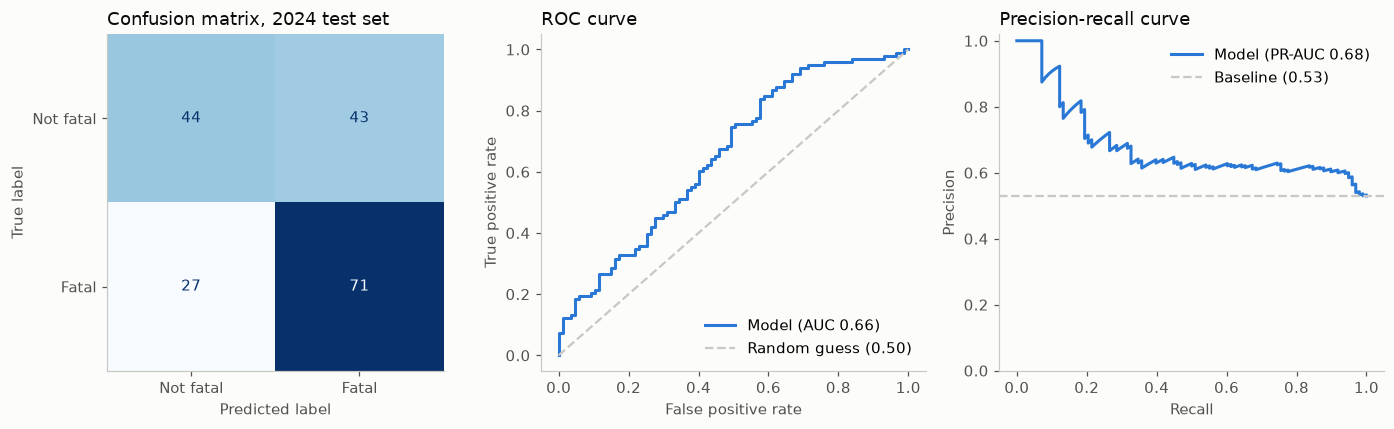

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

matrix = confusion_matrix(y_test, test_prediction)
ConfusionMatrixDisplay(matrix, display_labels=["Not fatal", "Fatal"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix, 2024 test set")

fpr, tpr, _ = roc_curve(y_test, test_probability)
axes[1].plot(fpr, tpr, color=BLUE, linewidth=2, label=f"Model (AUC {holdout_auc:.2f})")
axes[1].plot([0, 1], [0, 1], color=GREY, linewidth=1.5, linestyle="--", label="Random guess (0.50)")
axes[1].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend(loc="lower right")

curve_precision, curve_recall, _ = precision_recall_curve(y_test, test_probability)
axes[2].plot(curve_recall, curve_precision, color=BLUE, linewidth=2, label=f"Model (PR-AUC {holdout_ap:.2f})")
axes[2].axhline(y_test.mean(), color=GREY, linewidth=1.5, linestyle="--", label=f"Baseline ({y_test.mean():.2f})")
axes[2].set(title="Precision-recall curve", xlabel="Recall", ylabel="Precision", ylim=(0, 1.02))
axes[2].legend(loc="upper right")
plt.tight_layout()
plt.show()

## 5.4 Are the predicted probabilities reliable?

If the model says 60%, about 60% of those crashes should be fatal. Points near the dashed line mean the probabilities can be taken at face value.

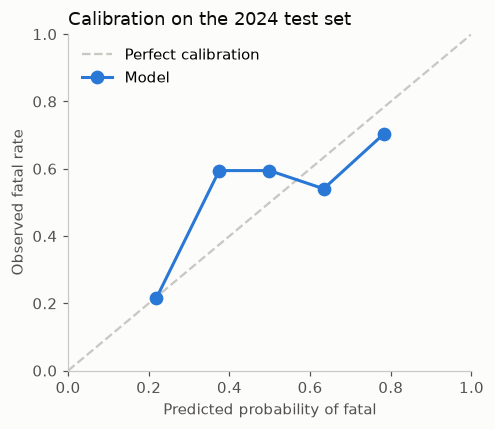

In [18]:
observed, predicted = calibration_curve(y_test, test_probability, n_bins=5, strategy="quantile")
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.plot([0, 1], [0, 1], color=GREY, linewidth=1.5, linestyle="--", label="Perfect calibration")
ax.plot(predicted, observed, color=BLUE, linewidth=2, marker="o", markersize=8, label="Model")
ax.set(title="Calibration on the 2024 test set", xlabel="Predicted probability of fatal", ylabel="Observed fatal rate", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## 5.5 Which features matter?

Permutation importance shuffles one feature at a time and measures how much test performance drops. The table then shows the actual fatal rate with and without each flag. These are **associations in reported crashes, not causes**.

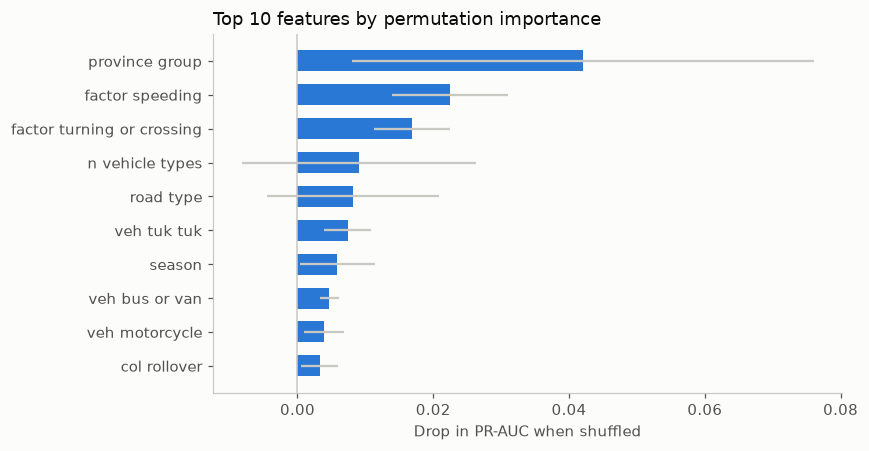

,crashes_with_flag,fatal_rate_with,fatal_rate_without,difference
veh_bus_or_van,20,0.750,0.386,0.364
factor_overtaking,32,0.719,0.381,0.338
veh_pedestrian,15,0.667,0.391,0.276
factor_wet_road_or_rain,17,0.647,0.390,0.257
veh_tractor,19,0.632,0.390,0.242
factor_wrong_way,68,0.559,0.379,0.180
factor_speeding,244,0.508,0.336,0.173
veh_heavy_truck,180,0.500,0.360,0.140
factor_careless_driving,108,0.500,0.377,0.123
veh_motorcycle,386,0.446,0.334,0.111


In [19]:
importance = permutation_importance(final_model, X_test, y_test, scoring="average_precision", n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
ranked = pd.DataFrame({"feature": features, "drop_in_PR_AUC": importance.importances_mean, "sd": importance.importances_std}).sort_values("drop_in_PR_AUC", ascending=False)

top = ranked.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.feature.str.replace("_", " "), top.drop_in_PR_AUC, xerr=top.sd, color=BLUE, height=0.62, error_kw={"ecolor": GREY, "lw": 1.5})
ax.axvline(0, color=GREY, linewidth=1)
ax.set(title="Top 10 features by permutation importance", xlabel="Drop in PR-AUC when shuffled")
plt.tight_layout()
plt.show()

flags = [c for c in numeric if c != "n_vehicle_types"]
effects = pd.DataFrame({"crashes_with_flag": [model_data[c].sum() for c in flags],
                        "fatal_rate_with": [model_data.loc[model_data[c] == 1, "is_fatal"].mean() for c in flags],
                        "fatal_rate_without": [model_data.loc[model_data[c] == 0, "is_fatal"].mean() for c in flags]}, index=flags)
effects["difference"] = effects.fatal_rate_with - effects.fatal_rate_without
display(effects[effects.crashes_with_flag >= 15].sort_values("difference", ascending=False).round(3))

## 5.6 Robustness checks

A trustworthy result should survive reasonable changes. Each row below refits the selected model with one change. The first row is the reference. These checks describe the model and are not used to choose it.

In [20]:
def fit_and_score(train, test, cat_cols=None, num_cols=None):
    model = make_pipeline(best_model.named_steps["clf"], cat_cols, num_cols).fit(train, train.is_fatal)
    probability = model.predict_proba(test)[:, 1]
    return {"train rows": len(train), "test rows": len(test), "ROC-AUC": roc_auc_score(test.is_fatal, probability),
            "PR-AUC": average_precision_score(test.is_fatal, probability), "test fatal rate": test.is_fatal.mean()}


random_train, random_test = train_test_split(model_data, test_size=len(test_df), stratify=model_data.is_fatal, random_state=RANDOM_STATE)
with_rewrites = model_data_all[model_data_all.year < TEST_FROM_YEAR]
factor_flags = [c for c in numeric if c.startswith("factor_")]
phnom_penh = (train_df[train_df.province == "Phnom Penh"], test_df[test_df.province == "Phnom Penh"])

robustness = pd.DataFrame({
    "Reference: train to 2023, test 2024": fit_and_score(train_df, test_df),
    "Random split instead of time split": fit_and_score(random_train, random_test),
    "Train also on suspected AI rewrites": fit_and_score(with_rewrites, test_df),
    "Without province": fit_and_score(train_df, test_df, [c for c in categorical if c != "province_group"], numeric),
    "Without stated factors": fit_and_score(train_df, test_df, categorical, [c for c in numeric if c not in factor_flags]),
    "Phnom Penh only": fit_and_score(*phnom_penh),
}).T
display(robustness.astype({"train rows": int, "test rows": int}).round(3))

# Does the text model from Step 4.3 hold up on 2024? This is a description only: it cannot replace the model chosen above.
hidden_test = test_df.Crash_Description.fillna("").str.replace(OUTCOME_WORDS, " ", regex=True)
text_probability = text_model().fit(masked_text, y_train).predict_proba(hidden_test)[:, 1]
print(f"Text with outcome words hidden, 2024 test ROC-AUC: {roc_auc_score(y_test, text_probability):.3f}")

,train rows,test rows,ROC-AUC,PR-AUC,test fatal rate
"Reference: train to 2023, test 2024",506,185,0.655,0.682,0.530
Random split instead of time split,506,185,0.814,0.742,0.395
Train also on suspected AI rewrites,527,185,0.650,0.675,0.530
Without province,506,185,0.665,0.693,0.530
Without stated factors,506,185,0.629,0.645,0.530
Phnom Penh only,256,99,0.699,0.599,0.434


Text with outcome words hidden, 2024 test ROC-AUC: 0.879


## 5.7 Where does the model fail?

Overall scores can hide weak spots. This splits test performance by region and shows some of the most confident mistakes for a person to read.

In [21]:
scored = test_df.assign(probability=test_probability, prediction=test_prediction)
rows = []
for group, part in scored.groupby("province_group"):
    if len(part) >= 15 and part.is_fatal.nunique() == 2:
        rows.append({"province group": group, "crashes": len(part), "fatal rate": part.is_fatal.mean(),
                     "ROC-AUC": roc_auc_score(part.is_fatal, part.probability), "recall": recall_score(part.is_fatal, part.prediction)})
display(pd.DataFrame(rows).set_index("province group").sort_values("crashes", ascending=False).round(3))

scored["error"] = (scored.is_fatal - scored.probability).abs()
columns = ["filename", "severity", "probability", "province_group", "time_of_day", "road_type", "vehicles_involved", "stated_factors"]
display(scored.sort_values("error", ascending=False)[columns].head(8).round(3))

,crashes,fatal rate,ROC-AUC,recall
province group,,,,
Phnom Penh,99,0.434,0.692,0.488
Other,61,0.607,0.641,1.000


,filename,severity,probability,province_group,time_of_day,road_type,vehicles_involved,stated_factors
651,accident-57.txt,Fatal,0.103,Phnom Penh,Night (21-04),City street,car_or_light_vehicle,NaN
161,accident-12.txt,Fatal,0.138,Phnom Penh,Evening (17-20),City street,car_or_light_vehicle,NaN
622,accident-541.txt,Fatal,0.179,Phnom Penh,Night (21-04),Unclassified,motorcycle; car_or_light_vehicle; tuk_tuk,drunk_driving; lost_control
525,accident-450.txt,Injury,0.816,Other,Afternoon (12-16),National road,motorcycle; car_or_light_vehicle,careless_driving
665,accident-582.txt,Injury,0.797,Other,Morning (05-11),National road,motorcycle; car_or_light_vehicle,speeding; wrong_way; turning_or_crossing
424,accident-359.txt,Fatal,0.207,Phnom Penh,Night (21-04),Unclassified,motorcycle,speeding; lost_control
538,accident-462.txt,Injury,0.790,Other,Morning (05-11),National road,car_or_light_vehicle; heavy_truck; tuk_tuk,speeding; wrong_way; lost_control; fatigue
272,accident-220.txt,Injury,0.783,Other,Unknown,National road,motorcycle; car_or_light_vehicle,NaN


## 5.8 Evaluation summary

_Findings are written after the notebook has run._

---
# Step 6. Deployment

## 6.1 Refit on all usable data and save

Now that the approach is fixed, the final model learns from every usable row, including 2024. Its expected performance is the Step 5 result.

In [22]:
deployed_model = make_pipeline(best_model.named_steps["clf"]).fit(model_data[features], model_data.is_fatal)
joblib.dump({"model": deployed_model, "threshold": THRESHOLD, "features": features, "top_provinces": TOP_PROVINCES}, MODEL_PATH)
print(f"Saved {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1024:.0f} KB), trained on {len(model_data)} crashes")

Saved road_severity_model.joblib (2457 KB), trained on 691 crashes


## 6.2 Use the saved model

`predict_crash` loads the file and scores one crash. Anything you leave out is treated as unknown or not reported.

In [23]:
def predict_crash(bundle, **details):
    row = {name: "Unknown" if name in categorical else 0 for name in bundle["features"]}
    row.update(details)
    if "province" in row:
        province = row.pop("province")
        row["province_group"] = province if province in bundle["top_provinces"] else "Other"
    probability = bundle["model"].predict_proba(pd.DataFrame([row])[bundle["features"]])[0, 1]
    return {"fatal_probability": round(float(probability), 3), "flagged_as_fatal": bool(probability >= bundle["threshold"])}


# joblib files can run code when loaded, so only load model files you created yourself.
bundle = joblib.load(MODEL_PATH)
scenarios = {
    "Night, national road, motorcycle and truck, speeding": dict(time_of_day="Night (21-04)", province="Kampong Speu", road_type="National road",
                                                                  veh_motorcycle=1, veh_heavy_truck=1, factor_speeding=1, n_vehicle_types=2),
    "Evening, city street, two cars, no factor stated": dict(time_of_day="Evening (17-20)", province="Phnom Penh", road_type="City street",
                                                              veh_car_or_light_vehicle=1, n_vehicle_types=1),
}
display(pd.DataFrame({name: predict_crash(bundle, **details) for name, details in scenarios.items()}).T)

,fatal_probability,flagged_as_fatal
"Night, national road, motorcycle and truck, speeding",0.676,True
"Evening, city street, two cars, no factor stated",0.233,False


## 6.3 Model card

_Findings are written after the notebook has run._